In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load data
sir = pd.read_csv("C:/Users/atrij/Downloads/India.csv")

# Preview of the data
print(sir.head())

   Unnamed: 0        Date  days  susceptible.pred  infected.pred  removed.pred
0           1  29-01-2020    29      1.339000e+09       0.043589      0.000000
1          11  30-01-2020    30      1.339000e+09       0.051561      0.000928
2          21  31-01-2020    31      1.339000e+09       0.060990      0.002025
3          31  01-02-2020    32      1.339000e+09       0.072142      0.003322
4          41  02-02-2020    33      1.339000e+09       0.085334      0.004857


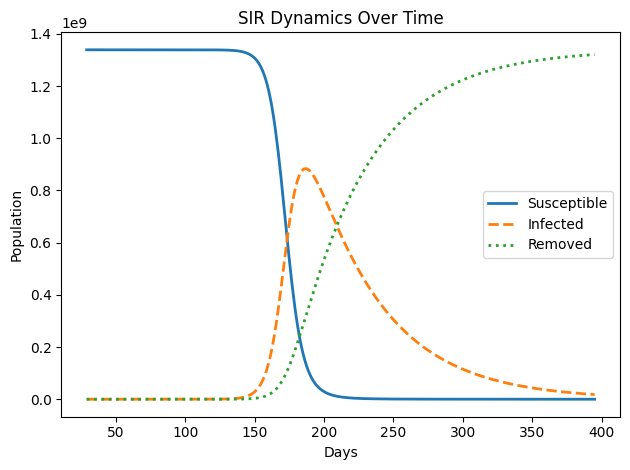

In [ ]:
# SIR VISUALISATION 

# Extract variables
t = sir["days"]
S = sir["susceptible.pred"]
I = sir["infected.pred"]
R = sir["removed.pred"]

#1. S, I, R vs Time
plt.figure()

plt.plot(t, S, linestyle='-', linewidth=2, label="Susceptible")   # solid
plt.plot(t, I, linestyle='--', linewidth=2, label="Infected")     # dashed
plt.plot(t, R, linestyle=':', linewidth=2, label="Removed")      # dotted

plt.xlabel("Days")
plt.ylabel("Population")
plt.title("SIR Dynamics Over Time")
plt.legend()
plt.tight_layout()
plt.show()



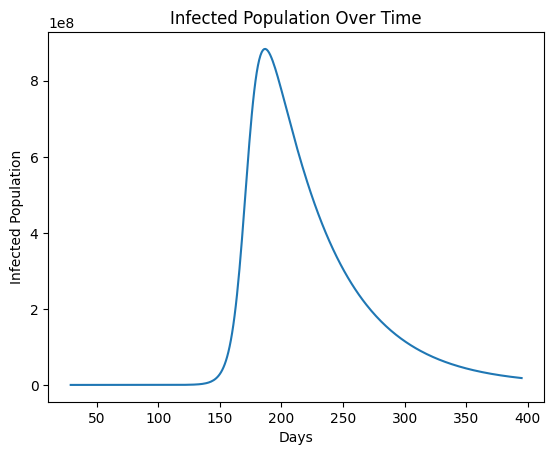

In [ ]:
#2. Infected vs Time
plt.figure()
plt.plot(t, I)
plt.xlabel("Days")
plt.ylabel("Infected Population")
plt.title("Infected Population Over Time")
plt.show()



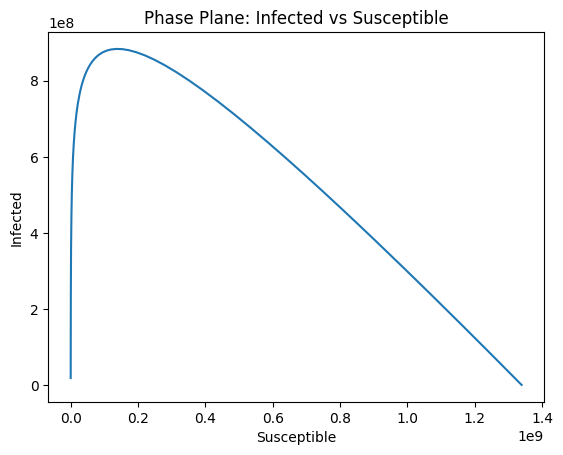

In [ ]:
#3. Phase Plot: I vs S
plt.figure()
plt.plot(S, I)
plt.xlabel("Susceptible")
plt.ylabel("Infected")
plt.title("Phase Plane: Infected vs Susceptible")
plt.show()



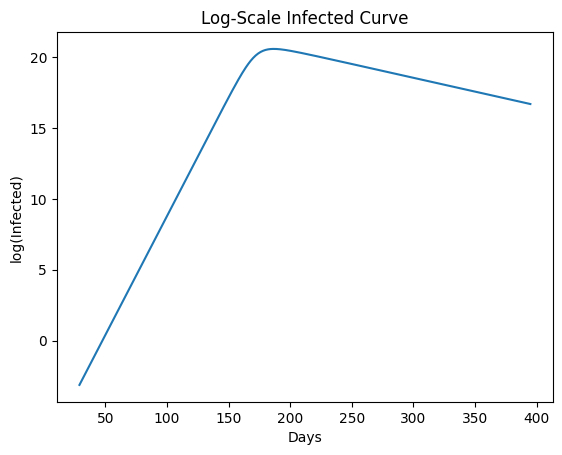

In [ ]:
#4. Log-scale Infected Curve
plt.figure()
plt.plot(t, np.log(I + 1e-8))
plt.xlabel("Days")
plt.ylabel("log(Infected)")
plt.title("Log-Scale Infected Curve")
plt.show()



In [ ]:
# 5. Daily beta(t) and gamma(t)
# Compute finite differences
dS = np.diff(S)
dR = np.diff(R)
S_mid = S[:-1]
I_mid = I[:-1]
N = S.iloc[0] + I.iloc[0] + R.iloc[0]

beta_t = -N * dS / (S_mid * I_mid)
gamma_t = dR / I_mid

# Clean values
beta_t = beta_t[np.isfinite(beta_t) & (beta_t > 0)]
gamma_t = gamma_t[np.isfinite(gamma_t) & (gamma_t > 0)]



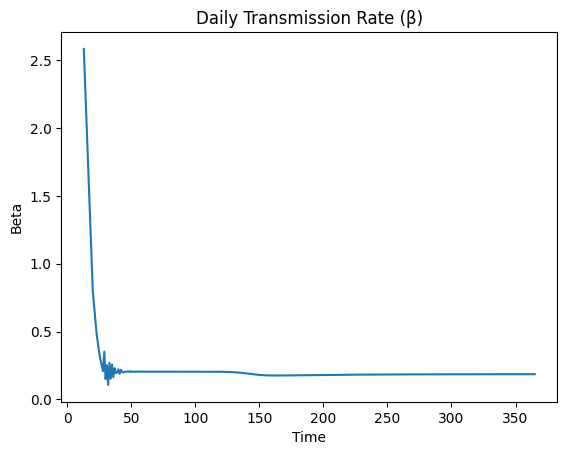

In [ ]:
# Plot beta
plt.figure()
plt.plot(beta_t)
plt.xlabel("Time")
plt.ylabel("Beta")
plt.title("Daily Transmission Rate (β)")
plt.show()


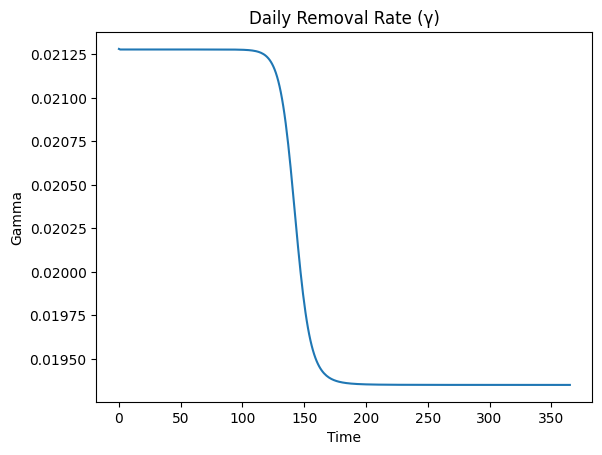

In [ ]:
# Plot gamma
plt.figure()
plt.plot(gamma_t)
plt.xlabel("Time")
plt.ylabel("Gamma")
plt.title("Daily Removal Rate (γ)")
plt.show()